# m11 - Data Quality: Does the Soil Gap-Fill Matter?

SoilGrids has no value for about 15 % of the cells (built-up land, water, mangrove edges). The warehouse fills them by
interpolation and keeps both versions: `soil_*` (gap-filled, used everywhere else) and `soil_*_raw` (NaN where SoilGrids had
nothing), plus the flag `soil_data_interpolated`.

1. **Where are the interpolated cells** and how do they differ?
2. **Input variants**: gap-filled soil, raw soil with NaN (boosting handles NaN natively), the flag added, no soil at all, and
   training on observed-soil cells only.
3. **Error split**: is the surrogate worse on the cells whose soil was invented?

In [1]:
import sys
from pathlib import Path

# Make exp_lib importable no matter where the notebook is launched from.
HERE = next(p for p in (Path.cwd(), Path.cwd() / "scripts" / "modeling") if (p / "exp_lib.py").exists())
sys.path.insert(0, str(HERE))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

import exp_lib as E
from threadpoolctl import threadpool_limits

threadpool_limits(E.N_JOBS)   # BLAS/OpenMP in this kernel stay within the same CPU budget as the worker pool
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 160)

1410 interpolated cells (15.4%)


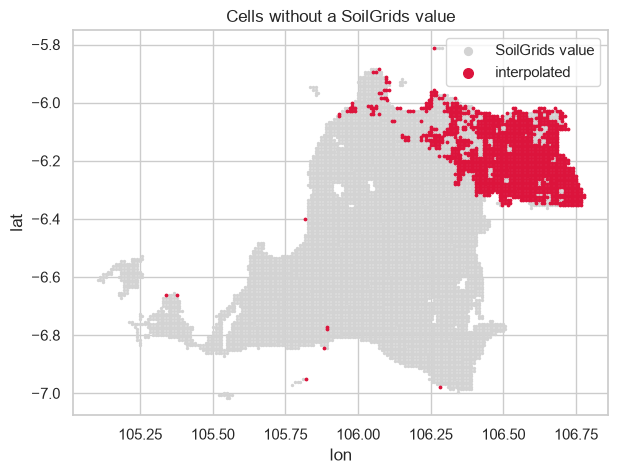

              elevation_mean_m  slope_mean_deg  cropland_pct  bio12_precip_annual_mm  bio1_temp_mean_c
interpolated                                                                                          
False                   175.27            8.65         15.03                 3094.07             24.93
True                     19.59            1.86         23.25                 2090.28             26.77

land-cover mix (WorldCover codes):
                    observed  interpolated
landcover_majority                        
10.0                   0.847         0.199
30.0                   0.004         0.030
40.0                   0.117         0.270
50.0                   0.020         0.437
60.0                   0.000         0.001
80.0                   0.010         0.061
90.0                   0.001         0.003
95.0                   0.001         0.000


In [2]:
df = E.load_table()
targets = {c: df[E.target_col(c)].to_numpy() for c in E.CROPS}   # GAEZ v5 at 1 km (E.TARGET_RES)
interp = df["soil_data_interpolated"].to_numpy(bool)
print(f"{interp.sum()} interpolated cells ({interp.mean():.1%})")

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(df.loc[~interp, "lon"], df.loc[~interp, "lat"], s=2, c="lightgrey", label="SoilGrids value")
ax.scatter(df.loc[interp, "lon"], df.loc[interp, "lat"], s=3, c="crimson", label="interpolated")
ax.set(aspect="equal", title="Cells without a SoilGrids value", xlabel="lon", ylabel="lat"); ax.legend(markerscale=4)
E.save_fig(fig, "m11_interpolated_cells")
plt.show()

wc = df.assign(interpolated=interp).groupby("interpolated")[["elevation_mean_m", "slope_mean_deg", "cropland_pct", "bio12_precip_annual_mm", "bio1_temp_mean_c"]].mean().round(2)
lc = pd.crosstab(df["landcover_majority"], interp, normalize="columns").round(3)
lc.columns = ["observed", "interpolated"]
print(wc.to_string()); print(); print("land-cover mix (WorldCover codes):"); print(lc.to_string())

## Input variants

In [3]:
G = E.FEATURE_GROUPS
soil, soil_raw = G["soil"], [f"{c}_raw" for c in G["soil"]]
no_soil = G["climate"] + G["terrain"]
df["soil_flag"] = interp.astype(float)
variants = {
    "gap-filled soil (as used)": G["climate"] + soil + G["terrain"],
    "raw soil with NaN": G["climate"] + soil_raw + G["terrain"],
    "gap-filled + interpolation flag": G["climate"] + soil + G["terrain"] + ["soil_flag"],
    "no soil": no_soil,
}
MODELS = ["et", "hgb", "xgb"]
parts, keep = [], {}
for name, cols in variants.items():
    r, oof = E.run_grid(df, targets, MODELS, ["pixel"], columns=cols, n_repeats=2, keep_oof=True, verbose=False)
    r["variant"] = name; parts.append(r); keep[name] = oof
res = pd.concat(parts, ignore_index=True)
E.save_table(res, "m11_soil_variants_raw")
tab = res.groupby(["variant", "model"])["r2"].mean().unstack("model").reindex(list(variants))
E.save_table(tab.round(4), "m11_soil_variants", index=True)
tab.round(3)

model,et,hgb,xgb
variant,,,
gap-filled soil (as used),0.820,0.808,0.809
raw soil with NaN,0.821,0.810,0.808
gap-filled + interpolation flag,0.823,0.809,0.808
no soil,0.818,0.810,0.806


## Train on observed-soil cells only
Cells with interpolated soil are removed from the *training* folds (they stay in the test folds).

In [4]:
# one scheme name per repeat so repeats stay separate
custom = {f"obs_only_r{rep}": E.make_splits(df, "pixel", seed=rep) for rep in range(2)}
custom = {k: [(tr[~interp[tr]], te) for tr, te in v] for k, v in custom.items()}
r_obs, oof_obs = E.run_grid(df, targets, MODELS, [], columns=variants["gap-filled soil (as used)"], custom_splits=custom, keep_oof=True, verbose=False)
obs_tab = r_obs.groupby("model")["r2"].mean()
full_tab = res[res.variant == "gap-filled soil (as used)"].groupby("model")["r2"].mean()
pd.DataFrame({"train on all cells": full_tab, "train on observed-soil cells only": obs_tab}).round(4)

,train on all cells,train on observed-soil cells only
model,,
et,0.820,0.6545
hgb,0.808,0.6688
xgb,0.809,0.6765


## Error split: observed vs interpolated cells

In [5]:
rows = []
for m in MODELS:
    for c in E.CROPS:
        pred = np.mean([keep["gap-filled soil (as used)"][(m, c, "pixel", r)] for r in range(2)], axis=0)
        for flag, name in [(False, "observed soil"), (True, "interpolated soil")]:
            sel = interp == flag
            rows.append({"model": m, "crop": c, "cells": name, **E.regression_metrics(targets[c][sel], pred[sel])})
split = pd.DataFrame(rows)
st = split.groupby(["model", "cells"])[["r2", "rmse", "mae", "spearman"]].mean().round(3)
E.save_table(st, "m11_error_split", index=True)
st

r2      rmse       mae  spearman
model cells                                                 
et    interpolated soil  0.655  1493.329  1059.120     0.797
      observed soil      0.862   690.020   449.673     0.933
hgb   interpolated soil  0.651  1499.554  1026.273     0.782
      observed soil      0.851   716.853   463.287     0.928
xgb   interpolated soil  0.647  1508.753  1043.540     0.785
      observed soil      0.852   715.932   466.037     0.927